# Telecom Customer Churn Analysis
### Exploratory Data Analysis (EDA) and Customer Retention Insights


## 1. Introduction

In the telecommunications industry, customer retention is important because losing existing customers can affect revenue and business growth.
This project focuses on analyzing customer data from a telecommunications company to understand customer behavior, identify patterns associated with churn, and discover factors that may influence customer retention.



## 3. Project Objectives

- Understand the structure and characteristics of the dataset.
- Clean and preprocess the customer data.
- Analyze customer demographics and subscription patterns.
- Investigate the relationship between customer services and churn.
- Examine customer tenure and billing behavior.
- Identify customer segments with higher churn rates.
- Extract meaningful insights through data visualizations.
- Provide business recommendations to improve customer retention.

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

# Makes chart cleaner
sns.set_style("whitegrid")

In [3]:
df=pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.shape

(7043, 21)

In [8]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [9]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [10]:
df.describe(include='object')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


# Data cleaning and preprocessing

In [11]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [16]:
#count blank or white-space only values

df['TotalCharges'].astype(str).str.strip().eq('').sum()

np.int64(11)

In [17]:
# Display records with blank TotalCharges
df[df['TotalCharges'].astype(str).str.strip()=='']

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


##### All these customers has atenure of zero months.
##### This suggests that these customers have just joined the company and have not accumulated any charges yet.

In [19]:
# Convert TotalCharges into numeric format
df['TotalCharges']=pd.to_numeric(df['TotalCharges'].str.strip(),errors='coerce')
df['TotalCharges'].dtype

dtype('float64')

In [20]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

### Since we investigated these records and found that all 11 customers have zero tenure, we can replace their missing total charges with zero.

In [21]:
df['TotalCharges']=df['TotalCharges'].fillna(0)

In [22]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [39]:
df['Tenuregroup']=pd.cut(df['tenure'],
                        bins=[-1,12,24,48,72],
                        labels=['New','Short-term','Medium-term','Long-term'])
df[['tenure','Tenuregroup']].head(10)

,tenure,Tenuregroup
0,1,New
1,34,Medium-term
2,2,New
3,45,Medium-term
4,2,New
5,8,New
6,22,Short-term
7,10,New
8,28,Medium-term
9,62,Long-term


In [40]:
df['MonthlyChargeCategory'] = pd.cut(
    df['MonthlyCharges'],
    bins=[-np.inf, 35, 70, np.inf],
    labels=['Low', 'Medium', 'High']
)

df[['MonthlyCharges', 'MonthlyChargeCategory']].head(10)

,MonthlyCharges,MonthlyChargeCategory
0,29.85,Low
1,56.95,Medium
2,53.85,Medium
3,42.30,Medium
4,70.70,High
5,99.65,High
6,89.10,High
7,29.75,Low
8,104.80,High
9,56.15,Medium


#### This feature will help us investigate whether customers paying higher monthly charges have different churn patterns.

In [41]:

# List of service columns

service_columns = [
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]


# Count the number of active services
df['TotalServices']=(df[service_columns]=='Yes').sum(axis=1)

df[['customerID', 'TotalServices', 'Churn']].head(10)

,customerID,TotalServices,Churn
0,7590-VHVEG,1,No
1,5575-GNVDE,2,No
2,3668-QPYBK,2,Yes
3,7795-CFOCW,3,No
4,9237-HQITU,0,Yes
5,9305-CDSKC,4,Yes
6,1452-KIOVK,3,No
7,6713-OKOMC,1,No
8,7892-POOKP,5,Yes
9,6388-TABGU,2,No


In [42]:
# Create spending categories using total charges

df['SpendingCategory'] = pd.cut(
    df['TotalCharges'],
    bins=[-np.inf, 500, 2000, np.inf],
    labels=['Low', 'Medium', 'High']
)

df[['TotalCharges', 'SpendingCategory']].head(10)

,TotalCharges,SpendingCategory
0,29.85,Low
1,1889.50,Medium
2,108.15,Low
3,1840.75,Medium
4,151.65,Low
5,820.50,Medium
6,1949.40,Medium
7,301.90,Low
8,3046.05,High
9,3487.95,High


In [43]:

df[['Tenuregroup', 'MonthlyChargeCategory',
    'TotalServices', 'SpendingCategory']].head(10)


,Tenuregroup,MonthlyChargeCategory,TotalServices,SpendingCategory
0,New,Low,1,Low
1,Medium-term,Medium,2,Medium
2,New,Medium,2,Low
3,Medium-term,Medium,3,Medium
4,New,High,0,Low
5,New,High,4,Medium
6,Short-term,High,3,Medium
7,New,Low,1,Low
8,Medium-term,High,5,High
9,Long-term,Medium,2,High


In [44]:
df['gender'].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

### What is the distribution of customers by gender?

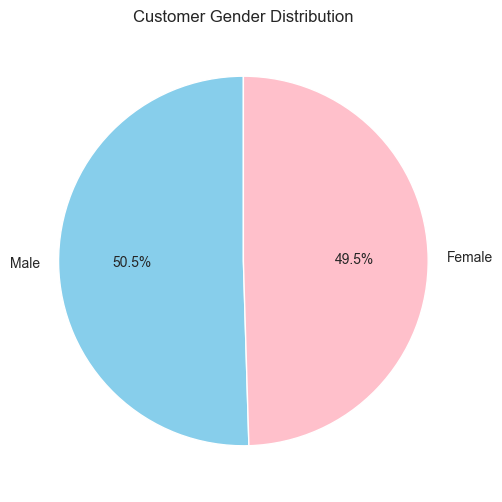

In [48]:
gender_count = df['gender'].value_counts()

plt.figure(figsize=(6, 6))

plt.pie(
    gender_count,
    labels=gender_count.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['skyblue', 'pink'])

plt.title('Customer Gender Distribution')
plt.show()

### How many customers are senior citizens?

In [49]:
df['SeniorCitizen'].value_counts()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

In [50]:
df['SeniorCitizenLabel'] = df['SeniorCitizen'].map({
    0: 'Non-Senior Citizen',
    1: 'Senior Citizen'
})

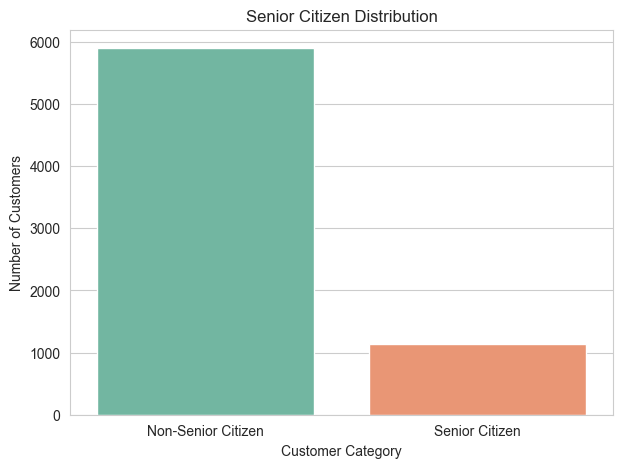

In [51]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='SeniorCitizenLabel',
    hue='SeniorCitizenLabel',
    palette='Set2',
    legend=False
)

plt.title('Senior Citizen Distribution')
plt.xlabel('Customer Category')
plt.ylabel('Number of Customers')
plt.show()

### Which contract type is most commonly used?

In [52]:
df['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

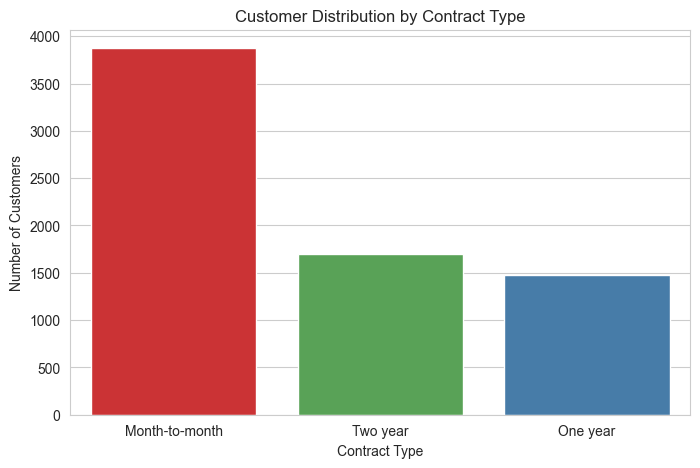

In [56]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Contract',
    palette='Set1',
    order=df['Contract'].value_counts().index, #sorts bars by frequency, largest first
    legend=False
)

plt.title('Customer Distribution by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()

In [57]:
df['tenure'].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

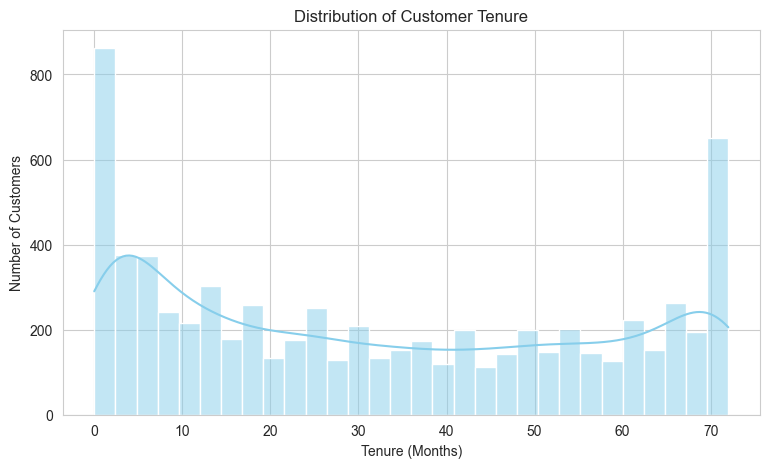

In [58]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='tenure',
    bins=30,
    kde=True,
    color='skyblue'
)

plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.show()

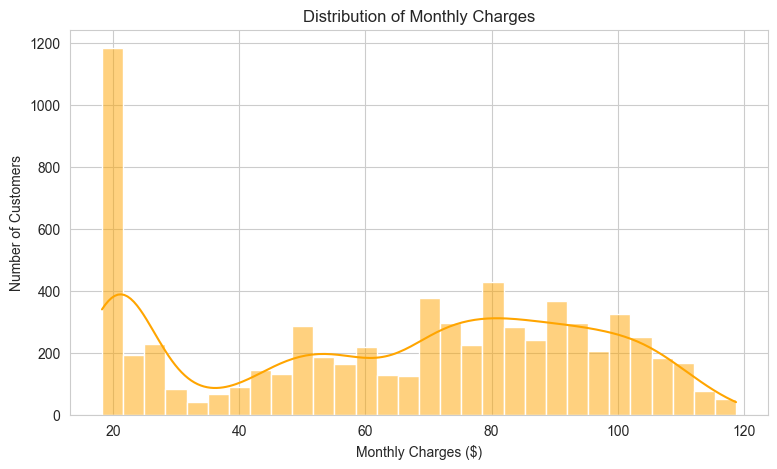

In [59]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='MonthlyCharges',
    bins=30,
    kde=True,
    color='orange'
)

plt.title('Distribution of Monthly Charges')
plt.xlabel('Monthly Charges ($)')
plt.ylabel('Number of Customers')
plt.show()

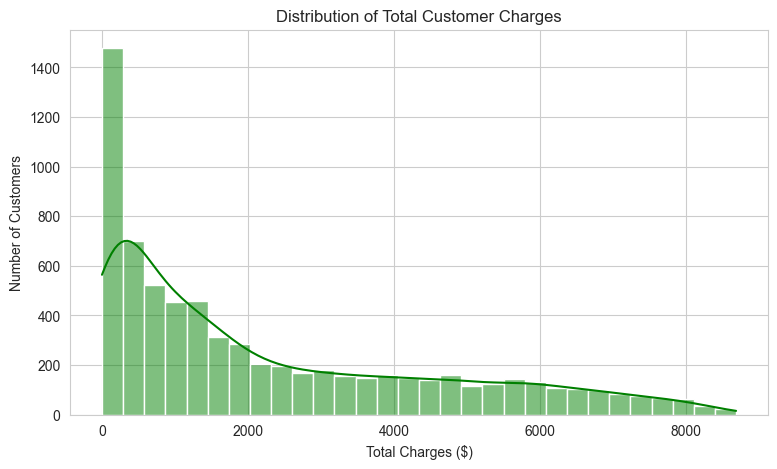

In [60]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='TotalCharges',
    bins=30,
    kde=True,
    color='green'
)

plt.title('Distribution of Total Customer Charges')
plt.xlabel('Total Charges ($)')
plt.ylabel('Number of Customers')
plt.show()

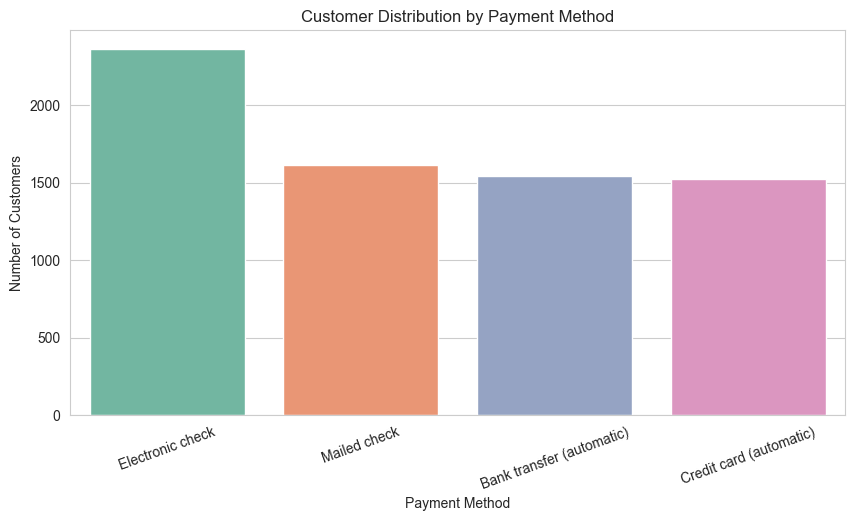

In [62]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='PaymentMethod',
    hue='PaymentMethod',
    palette='Set2',
    order=df['PaymentMethod'].value_counts().index,
    legend=False
)

plt.title('Customer Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20)
plt.show()

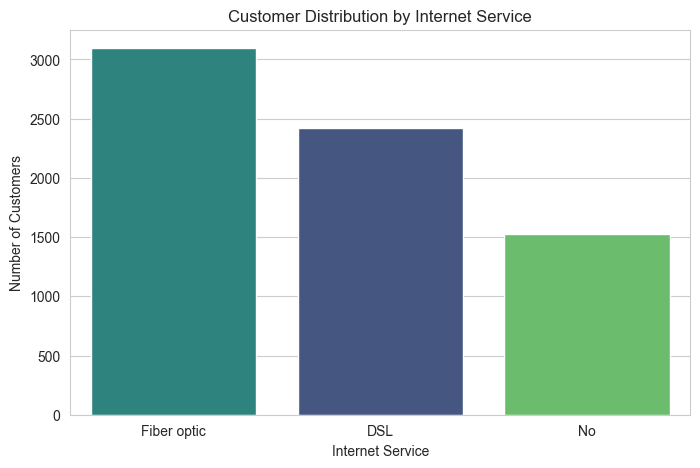

In [63]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='InternetService',
    hue='InternetService',
    palette='viridis',
    order=df['InternetService'].value_counts().index,
    legend=False
)

plt.title('Customer Distribution by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.show()

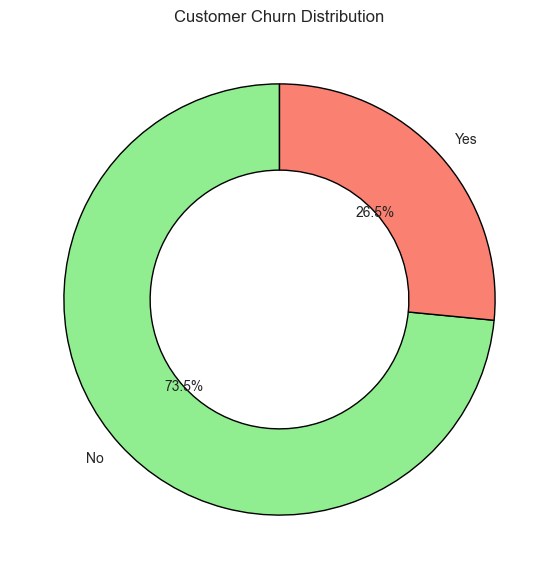

In [64]:
churn_count = df['Churn'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    churn_count,
    labels=churn_count.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['lightgreen', 'salmon'],
    wedgeprops={'width': 0.4, 'edgecolor': 'black'}
)

plt.title('Customer Churn Distribution')
plt.show()

### Are customers with short-term contracts more likely to leave than customers with long-term contracts?

In [65]:
pd.crosstab(df['Contract'], df['Churn'])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [67]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index' # calculates percentages row-wise
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


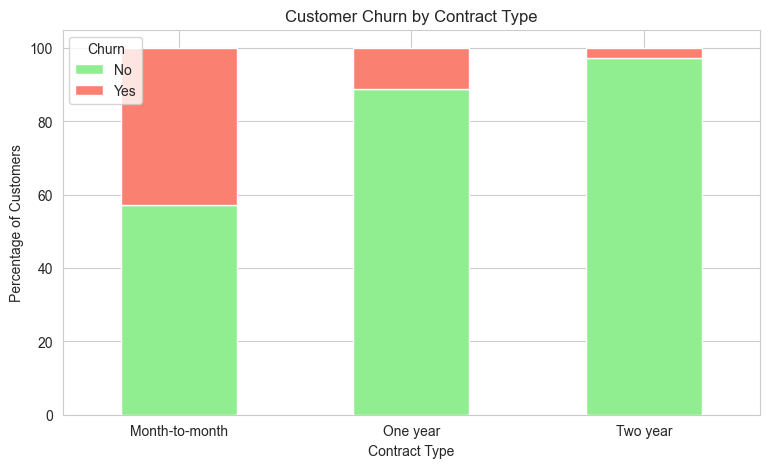

In [68]:
contract_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5),
    color=['lightgreen', 'salmon']
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Percentage of Customers')
plt.legend(title='Churn')
plt.xticks(rotation=0)
plt.show()

 ### Contract Type vs Customer Churn

The stacked bar chart shows a strong relationship between contract type and customer churn.

Customers with month-to-month contracts have the highest churn rate of approximately 42.7%. In comparison, customers with one-year contracts have a churn rate of approximately 11.3%, while customers with two-year contracts have the lowest churn rate of approximately 2.8%.

This indicates that customers with shorter contract commitments are more likely to leave the company than customers with long-term contracts.

Therefore, the company should encourage customers to choose long-term contracts by providing attractive offers, discounts, and additional benefits.

### Monthly Charges vs Customer Churn

In [69]:
df.groupby('Churn')['MonthlyCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


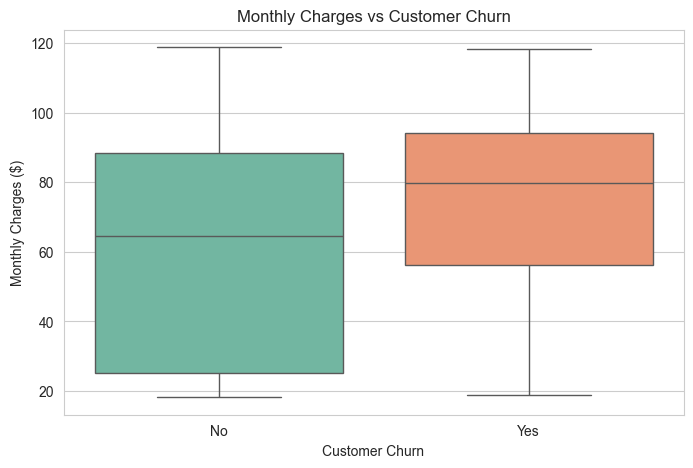

In [70]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Customer Churn')
plt.ylabel('Monthly Charges ($)')
plt.show()

### 1. Median monthly charges
- Customers who did not churn (No): Median is approximately $64.

- Customers who churned (Yes): Median is approximately $80.
  
This indicates that customers who left the company generally had higher monthly charges.

###  Monthly Charges vs Customer Churn

The box plot shows a difference in monthly charges between customers who churned and those who stayed.

Customers who churned have a higher median monthly charge (approximately $80) compared to customers who stayed (approximately $64). This suggests that customers paying higher monthly charges may be more likely to leave the company.

Therefore, monthly charges may be an important factor to investigate when understanding customer churn.

### Customer Tenure vs Customer Churn

In [72]:
df.groupby('Churn')['tenure'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


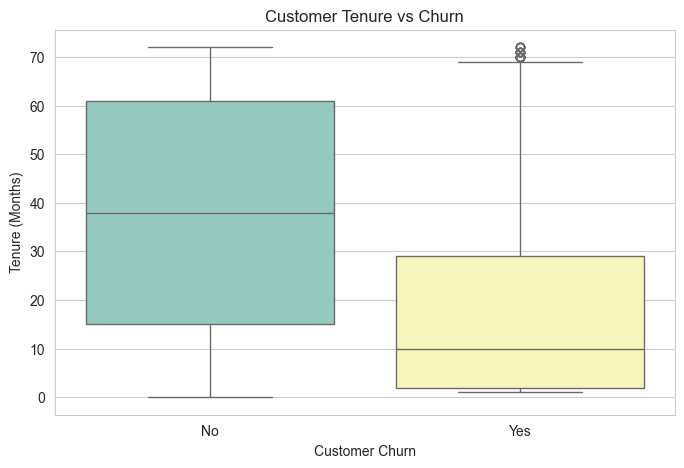

In [73]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='tenure',
    hue='Churn',
    palette='Set3',
    legend=False
)

plt.title('Customer Tenure vs Churn')
plt.xlabel('Customer Churn')
plt.ylabel('Tenure (Months)')
plt.show()

###  Customer Tenure vs Customer Churn

The box plot shows a clear difference in customer tenure between customers who churned and those who stayed.

Customers who stayed with the company have a median tenure of approximately 38 months, whereas customers who churned have a median tenure of approximately 10 months.

This indicates that customers with shorter tenure are more likely to leave the company. The distribution also shows that most churned customers are concentrated in the lower tenure range.

Therefore, the company should focus more on retaining new customers and improving their early customer experience.

### Internet Service vs Customer Churn

In [75]:
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


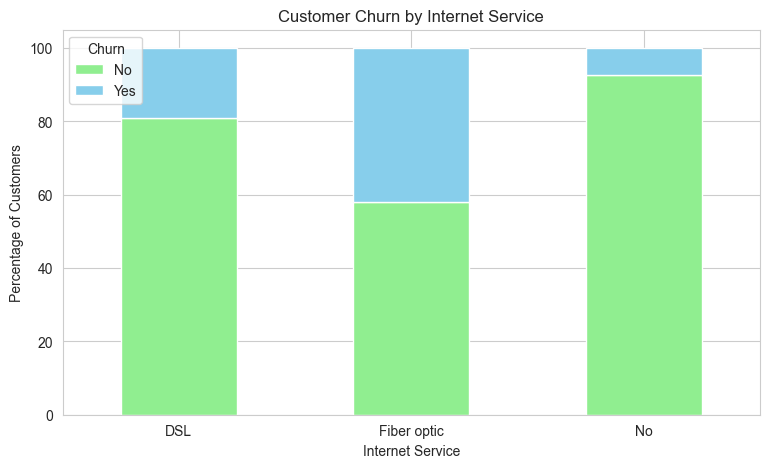

In [78]:
internet_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5),
    color=['lightgreen', 'skyblue']
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Percentage of Customers')
plt.legend(title='Churn')
plt.xticks(rotation=0)
plt.show()

### Internet Service vs Customer Churn

The stacked bar chart shows that customer churn varies across different internet service categories.

Fiber optic customers have the highest churn rate of approximately 41.9%, followed by DSL customers at approximately 19%. Customers who do not use internet services have the lowest churn rate of approximately 7.4%.

This indicates that customers using fiber optic internet are more likely to leave the company compared to customers using other internet service categories.

Therefore, the company should investigate possible issues related to fiber optic services, such as pricing, service quality, and customer satisfaction, to identify the reasons behind the higher churn rate.

### Payment Method vs Customer Churn

In [79]:
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


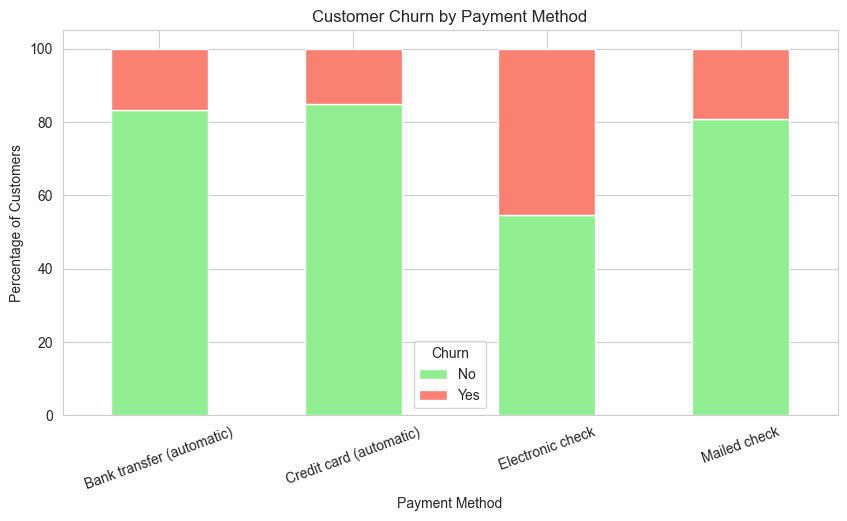

In [80]:
payment_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5),
    color=['lightgreen', 'salmon']
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Percentage of Customers')
plt.legend(title='Churn')
plt.xticks(rotation=20)
plt.show()



 ### Payment Method vs Customer Churn

The stacked bar chart shows that customer churn varies depending on the payment method.

Customers using electronic checks have the highest churn rate of approximately 45.3%. In comparison, customers using bank transfers have a churn rate of approximately 16.7%, credit card users have 15.2%, and mailed check users have 19.1%.

This indicates that customers using electronic checks are more likely to leave the company than customers using other payment methods.

Therefore, the company should investigate the reasons behind the higher churn among electronic check users and encourage convenient automatic payment options.

In [81]:
techsupport_churn = pd.crosstab(
    df['TechSupport'],
    df['Churn'],
    normalize='index'
) * 100

techsupport_churn

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


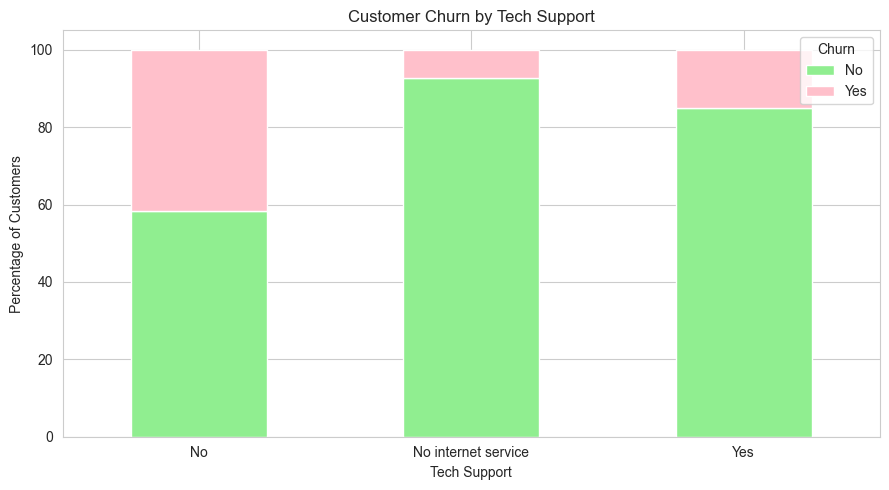

In [83]:
techsupport_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5),
    color=['lightgreen', 'pink']
)

plt.title('Customer Churn by Tech Support')
plt.xlabel('Tech Support')
plt.ylabel('Percentage of Customers')
plt.legend(title='Churn')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### For internet customers, not having Tech Support is a major red flag for churn. The marketing and customer success teams should focus on bundling Tech Support into internet packages, or offering it at a discount during the first 6 months, as a targeted strategy to reduce overall customer loss

In [84]:
security_churn = pd.crosstab(
    df['OnlineSecurity'],
    df['Churn'],
    normalize='index'
) * 100

security_churn

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


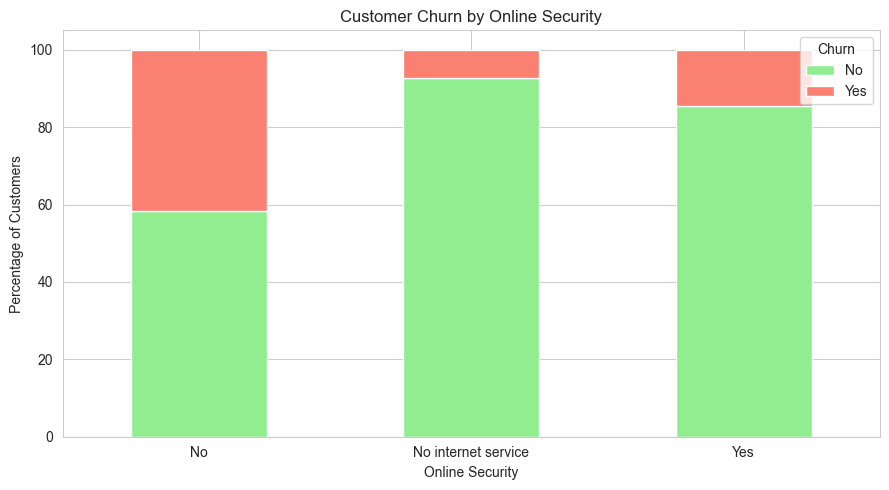

In [85]:
security_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5),
    color=['lightgreen', 'salmon']
)

plt.title('Customer Churn by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Percentage of Customers')
plt.legend(title='Churn')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

 ### Online Security vs Customer Churn

The analysis shows that customers who do not have online security have the highest churn rate of approximately 41.8%. In comparison, customers who have online security have a churn rate of approximately 14.6%, while customers without internet service have a churn rate of approximately 7.4%.

This indicates that customers using online security services are less likely to leave the company.

Therefore, the company should promote online security services and investigate whether customers without these services have additional security concerns or unmet needs.

In [86]:
services_churn = pd.crosstab(
    df['TotalServices'],
    df['Churn'],
    normalize='index'
) * 100

services_churn

Churn,No,Yes
TotalServices,,
0,79.244151,20.755849
1,65.544041,34.455959
2,62.277952,37.722048
3,68.711656,31.288344
4,74.276527,25.723473
5,78.254848,21.745152
6,88.333333,11.666667
7,94.711538,5.288462


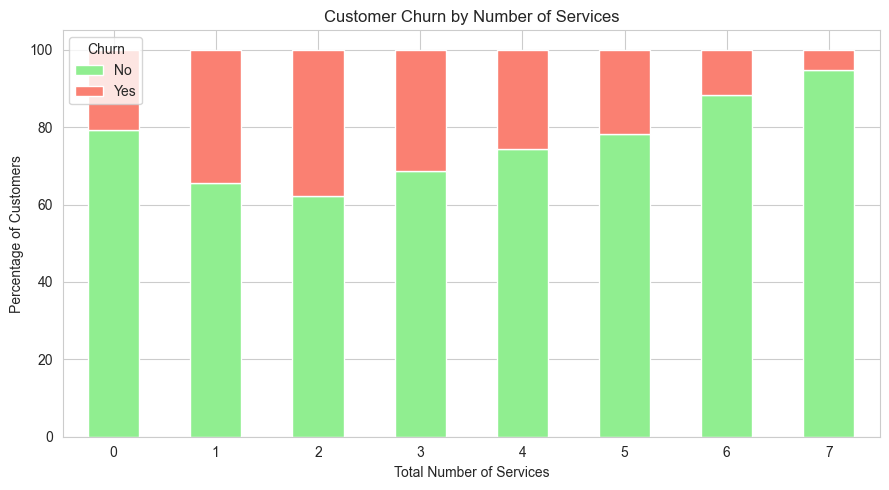

In [87]:
services_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5),
    color=['lightgreen', 'salmon']
)

plt.title('Customer Churn by Number of Services')
plt.xlabel('Total Number of Services')
plt.ylabel('Percentage of Customers')
plt.legend(title='Churn')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### It is harder for a customer to leave when they use many of your services. If they only have one service, they are easy to lose. The business should focus on bundling services together to keep customers around longer.



In [88]:
partner_churn = pd.crosstab(
    df['Partner'],
    df['Churn'],
    normalize='index'
) * 100

partner_churn

Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


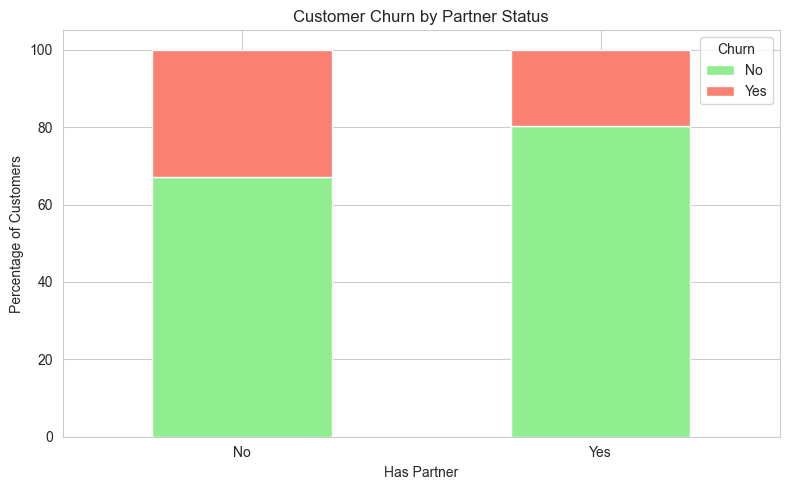

In [89]:
partner_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    color=['lightgreen', 'salmon']
)

plt.title('Customer Churn by Partner Status')
plt.xlabel('Has Partner')
plt.ylabel('Percentage of Customers')
plt.legend(title='Churn')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### Customers who live alone are a higher risk. The business should target single customers with special offers or bundles to encourage them to stay longer.



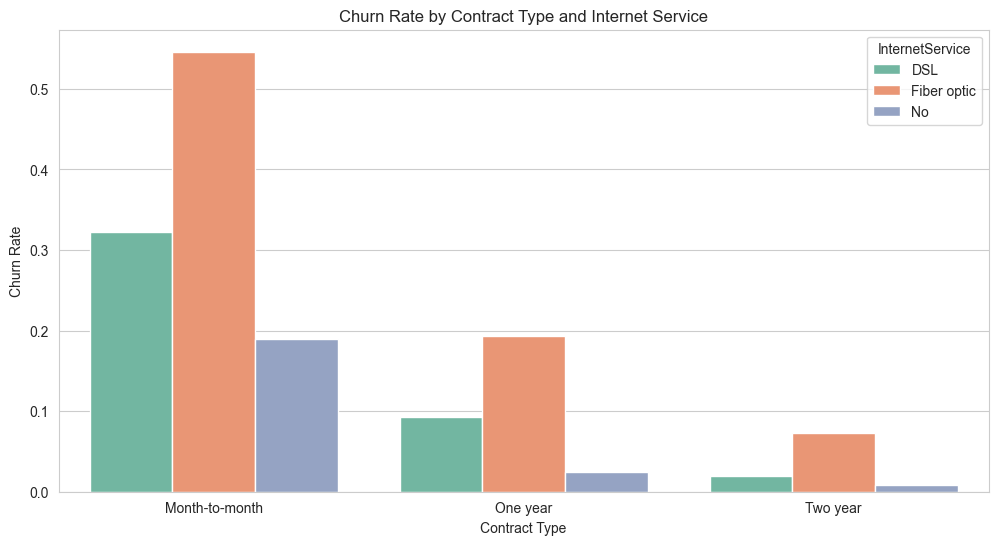

In [90]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x='Contract',
    y=df['Churn'].eq('Yes').astype(int),
    hue='InternetService',
    errorbar=None,
    palette='Set2'
)

plt.title('Churn Rate by Contract Type and Internet Service')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate')
plt.show()